In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sumanthvrao/daily-climate-time-series-data")

print("Path to dataset files:", path)

100%|██████████| 22.0k/22.0k [00:00<00:00, 24.0MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/sumanthvrao/daily-climate-time-series-data/versions/3


In [3]:
import os
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# List files in the downloaded dataset path
files = os.listdir(path)
print("Files in dataset directory:", files)

Files in dataset directory: ['DailyDelhiClimateTrain.csv', 'DailyDelhiClimateTest.csv']


In [8]:
# Task 1: Clean and normalize the weather features
# Convert date columns
train_df['date'] = pd.to_datetime(train_df['date'])
test_df['date'] = pd.to_datetime(test_df['date'])

train_df.set_index('date', inplace=True)
test_df.set_index('date', inplace=True)

# Handle anomalies in meanpressure (known issue in Daily Delhi Climate dataset with extreme outliers)
# Replacing values outside 900-1100 hPa range with median
for df in [train_df, test_df]:
    median_pressure = df['meanpressure'][(df['meanpressure'] >= 900) & (df['meanpressure'] <= 1100)].median()
    df.loc[(df['meanpressure'] < 900) | (df['meanpressure'] > 1100), 'meanpressure'] = median_pressure

# Scale the features
scaler = MinMaxScaler()
scaled_cols = ['meantemp', 'humidity', 'wind_speed', 'meanpressure']

train_scaled = pd.DataFrame(scaler.fit_transform(train_df[scaled_cols]), columns=scaled_cols, index=train_df.index)
test_scaled = pd.DataFrame(scaler.transform(test_df[scaled_cols]), columns=scaled_cols, index=test_df.index)

print("Data cleaning and scaling completed.")
print(train_scaled.head())

Data cleaning and scaling completed.
            meantemp  humidity  wind_speed  meanpressure
date                                                    
2013-01-01  0.122271  0.820957    0.000000      0.913658
2013-01-02  0.042795  0.907591    0.070583      0.938776
2013-01-03  0.035662  0.849835    0.109743      0.948980
2013-01-04  0.081514  0.668867    0.029212      0.931319
2013-01-05  0.000000  0.847910    0.087636      0.923469


In [9]:
# Task 2: Generate sequences using historical temperature and other relevant variables
def create_sequences(data, seq_length=14, target_col_idx=0):
    X = []
    y = []
    for i in range(len(data) - seq_length):
        X.append(data[i:i + seq_length])
        y.append(data[i + seq_length, target_col_idx])
    return np.array(X), np.array(y)

SEQ_LENGTH = 14 # use past 14 days to predict next day's temperature

train_values = train_scaled.values
test_values = test_scaled.values

# Pad test data with the end of train data to maintain sequence continuity for testing
combined_values = np.vstack([train_values[-SEQ_LENGTH:], test_values])

X_train, y_train = create_sequences(train_values, seq_length=SEQ_LENGTH)
X_test, y_test = create_sequences(combined_values, seq_length=SEQ_LENGTH)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1448, 14, 4)
y_train shape: (1448,)
X_test shape: (114, 14, 4)
y_test shape: (114,)


In [4]:
# Load the training and testing datasets (usually DailyDelhiClimateTrain.csv and DailyDelhiClimateTest.csv in this dataset)
train_file = [f for f in files if 'Train' in f][0]
test_file = [f for f in files if 'Test' in f][0]

train_df = pd.read_csv(os.path.join(path, train_file))
test_df = pd.read_csv(os.path.join(path, test_file))

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

print("\nTrain Columns & Info:")
display(train_df.info())
display(train_df.head())

Train shape: (1462, 5)
Test shape: (114, 5)

Train Columns & Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1462 entries, 0 to 1461
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          1462 non-null   object 
 1   meantemp      1462 non-null   float64
 2   humidity      1462 non-null   float64
 3   wind_speed    1462 non-null   float64
 4   meanpressure  1462 non-null   float64
dtypes: float64(4), object(1)
memory usage: 57.2+ KB


None

,date,meantemp,humidity,wind_speed,meanpressure
0,2013-01-01,10.000000,84.500000,0.000000,1015.666667
1,2013-01-02,7.400000,92.000000,2.980000,1017.800000
2,2013-01-03,7.166667,87.000000,4.633333,1018.666667
3,2013-01-04,8.666667,71.333333,1.233333,1017.166667
4,2013-01-05,6.000000,86.833333,3.700000,1016.500000


In [10]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

# Task 3: Select, justify and train a sequential model
# We choose LSTM as the sequential model because it is highly effective at capturing long-term dependencies in sequence/time-series data.
model = Sequential([
    LSTM(50, activation='relu', input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=False),
    Dropout(0.2),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.summary()

# Train the model
history = model.fit(
    X_train, y_train,
    epochs=35,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        11,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,051 (43.17 KB)

 Trainable params: 11,051 (43.17 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/35
41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.1239 - val_loss: 0.0101
Epoch 2/35
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0180 - val_loss: 0.0030
Epoch 3/35
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0137 - val_loss: 0.0026
Epoch 4/35
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0119 - val_loss: 0.0027
Epoch 5/35
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0119 - val_loss: 0.0026
Epoch 6/35
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0111 - val_loss: 0.0028
Epoch 7/35
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0099 - val_loss: 0.0028
Epoch 8/35
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0100 - val_loss: 0.0025
Epoch 9/35
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0092 - val_loss: 0.0025
Epoch 10/35
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0086 - val_loss: 0.0032
Epoch 11/35
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0087 - val_loss: 0.0023
Epoch 12/35
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0085

In [11]:
# Task 4: Evaluate the model using MAE and RMSE
predictions_scaled = model.predict(X_test)

# Create a dummy array to inverse scale predictions easily
dummy_pred = np.zeros((len(predictions_scaled), 4))
dummy_pred[:, 0] = predictions_scaled.flatten() # first column is meantemp
predictions = scaler.inverse_transform(dummy_pred)[:, 0]

dummy_true = np.zeros((len(y_test), 4))
dummy_true[:, 0] = y_test
y_test_actual = scaler.inverse_transform(dummy_true)[:, 0]

mae = mean_absolute_error(y_test_actual, predictions)
rmse = np.sqrt(mean_squared_error(y_test_actual, predictions))

print(f"\nTest MAE: {mae:.4f} °C")
print(f"Test RMSE: {rmse:.4f} °C")

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step

Test MAE: 1.6898 °C
Test RMSE: 2.0368 °C


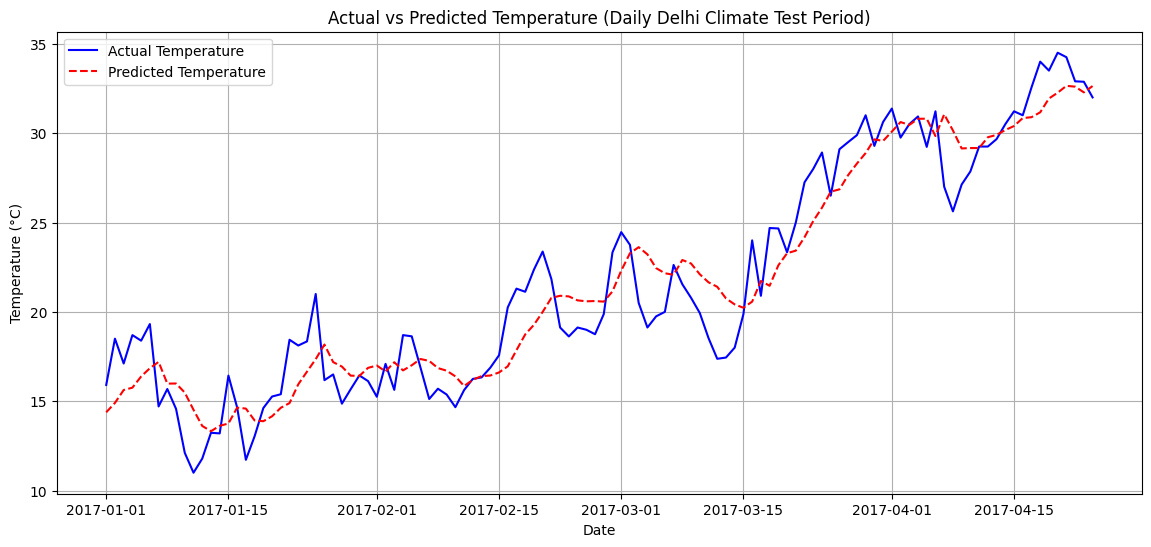

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step

7-Day Future Forecast on Unseen Dates:
2017-04-25: 32.37 °C
2017-04-26: 32.37 °C
2017-04-27: 32.42 °C
2017-04-28: 32.51 °C
2017-04-29: 32.62 °C
2017-04-30: 32.71 °C
2017-05-01: 32.81 °C


In [12]:
# Task 5: Plot actual vs predicted temperature & demonstrate forecasting on unseen dates
plt.figure(figsize=(14, 6))
plt.plot(test_df.index, y_test_actual, label='Actual Temperature', color='blue')
plt.plot(test_df.index, predictions, label='Predicted Temperature', color='red', linestyle='--')
plt.title('Actual vs Predicted Temperature (Daily Delhi Climate Test Period)')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.grid(True)
plt.show()

# Demonstrate forecasting on 7 unseen future dates
last_sequence = test_values[-SEQ_LENGTH:]
current_sequence = last_sequence.copy()

future_forecast_scaled = []
for _ in range(7):
    pred = model.predict(current_sequence.reshape(1, SEQ_LENGTH, 4))[0, 0]
    future_forecast_scaled.append(pred)
    # Roll sequence and insert prediction
    new_row = current_sequence[-1].copy()
    new_row[0] = pred
    current_sequence = np.vstack([current_sequence[1:], new_row])

dummy_future = np.zeros((7, 4))
dummy_future[:, 0] = future_forecast_scaled
future_predictions = scaler.inverse_transform(dummy_future)[:, 0]

future_dates = pd.date_range(start=test_df.index[-1] + pd.Timedelta(days=1), periods=7)
print("\n7-Day Future Forecast on Unseen Dates:")
for date, temp in zip(future_dates, future_predictions):
    print(f"{date.strftime('%Y-%m-%d')}: {temp:.2f} °C")